# EuroSAT Land-Use Classification with a CNN

For this project, we will use the EuroSAT dataset.

The dataset contains 10 classes:

AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial,
Pasture, PermanentCrop, Residential, River and SeaLake.

The images are RGB satellite images.

In Stage 1, we will:
- load the EuroSAT dataset
- create training, validation and test sets
- visualize some images
- define a CNN from scratch
- train the CNN
- evaluate its performance
- save the trained model

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [3]:
torch.manual_seed(42)

In [4]:
classes = (
    'AnnualCrop',
    'Forest',
    'HerbaceousVegetation',
    'Highway',
    'Industrial',
    'Pasture',
    'PermanentCrop',
    'Residential',
    'River',
    'SeaLake'
)

print(classes)

('AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake')


In [5]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = torchvision.datasets.EuroSAT(
    root='./data',
    download=True,
    transform=transform
)

print(dataset)

100.0%


Dataset EuroSAT
    Number of datapoints: 27000
    Root location: ./data
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )


In [6]:
print("Number of images:", len(dataset))
print("Classes:", dataset.classes)

Number of images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [7]:
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 18900
Validation images: 4050
Test images: 4050


In [8]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valloader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created")

DataLoaders created


In [9]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


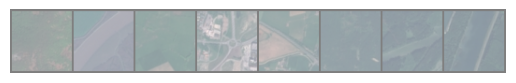

GroundTruth:           Forest           River         Pasture         Highway         Highway          Forest           River           River


In [10]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

imshow(torchvision.utils.make_grid(images[:8]))

print(
    'GroundTruth: ',
    ' '.join('%15s' % classes[labels[j]] for j in range(8))
)

In [11]:
class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(-1, 128 * 8 * 8)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x

In [12]:
net = Net()

print(net)

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [13]:
total_params = sum(p.numel() for p in net.parameters())

print("Total parameters:", total_params)

Total parameters: 2193226


In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    net.parameters(),
    lr=0.001
)

In [16]:
n_epochs = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(n_epochs):

    running_loss = 0.0
    correct = 0
    total = 0

    # Training
    net.train()

    for i, data in enumerate(trainloader, 0):

        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        # statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(trainloader)
    train_accuracy = correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation
    net.eval()

    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for data in valloader:

            images, labels = data

            outputs = net(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(valloader)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        '[%d] train loss: %.3f | train accuracy: %.2f%% | '
        'validation loss: %.3f | validation accuracy: %.2f%%'
        % (
            epoch + 1,
            train_loss,
            100 * train_accuracy,
            val_loss,
            100 * val_accuracy
        )
    )

print('Finished Training')

[1] train loss: 1.139 | train accuracy: 56.87% | validation loss: 0.734 | validation accuracy: 72.74%
[2] train loss: 0.672 | train accuracy: 75.42% | validation loss: 0.745 | validation accuracy: 72.57%
[3] train loss: 0.582 | train accuracy: 78.81% | validation loss: 0.579 | validation accuracy: 78.79%
[4] train loss: 0.488 | train accuracy: 82.10% | validation loss: 0.501 | validation accuracy: 82.44%
[5] train loss: 0.443 | train accuracy: 83.80% | validation loss: 0.464 | validation accuracy: 83.68%
[6] train loss: 0.392 | train accuracy: 86.13% | validation loss: 0.439 | validation accuracy: 83.85%
[7] train loss: 0.333 | train accuracy: 88.09% | validation loss: 0.414 | validation accuracy: 86.12%
[8] train loss: 0.278 | train accuracy: 90.10% | validation loss: 0.446 | validation accuracy: 84.59%
[9] train loss: 0.261 | train accuracy: 90.63% | validation loss: 0.418 | validation accuracy: 86.35%
[10] train loss: 0.215 | train accuracy: 92.26% | validation loss: 0.421 | validat

In [17]:
PATH = './baseline.pth'

torch.save(net.state_dict(), PATH)

print("Model saved as:", PATH)

Model saved as: ./baseline.pth


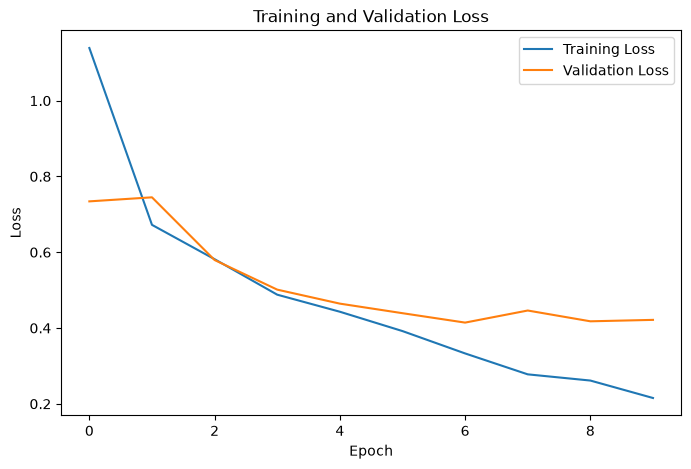

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title('Training and Validation Loss')

plt.legend()

plt.show()

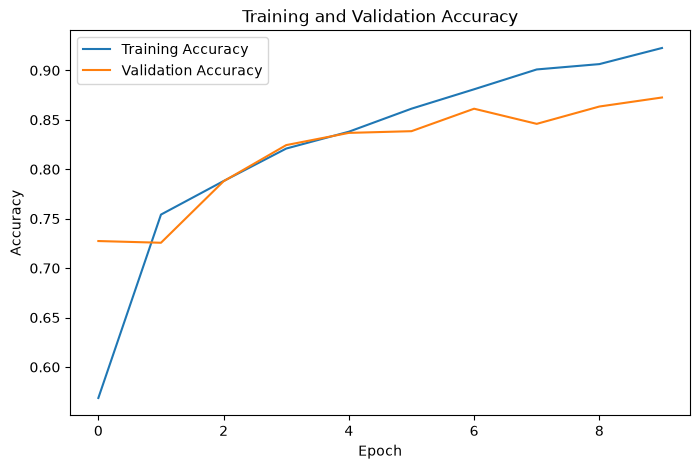

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title('Training and Validation Accuracy')

plt.legend()

plt.show()

In [22]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [23]:
PATH = './baseline.pth'

trainednet = Net()

trainednet.load_state_dict(
    torch.load(PATH, map_location=device)
)

trainednet = trainednet.to(device)

In [24]:
correct = 0
total = 0

with torch.no_grad():

    for data in testloader:

        images, labels = data

        outputs = trainednet(images)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

print(
    'Accuracy of the network on the test images: %d %%'
    % (100 * correct / total)
)

Accuracy of the network on the test images: 87 %


In [26]:
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))

with torch.no_grad():

    for data in testloader:

        images, labels = data

        images = images.to(device)
        labels = labels.to(device)

        outputs = trainednet(images)

        _, predicted = torch.max(outputs, 1)

        c = (predicted == labels)

        for i in range(len(labels)):

            label = labels[i]

            class_correct[label] += c[i].item()
            class_total[label] += 1

In [27]:
for i in range(10):

    print(
        'Accuracy of %25s : %2d %%'
        % (
            classes[i],
            100 * class_correct[i] / class_total[i]
        )
    )

Accuracy of                AnnualCrop : 90 %
Accuracy of                    Forest : 98 %
Accuracy of      HerbaceousVegetation : 83 %
Accuracy of                   Highway : 80 %
Accuracy of                Industrial : 85 %
Accuracy of                   Pasture : 80 %
Accuracy of             PermanentCrop : 76 %
Accuracy of               Residential : 97 %
Accuracy of                     River : 80 %
Accuracy of                   SeaLake : 93 %


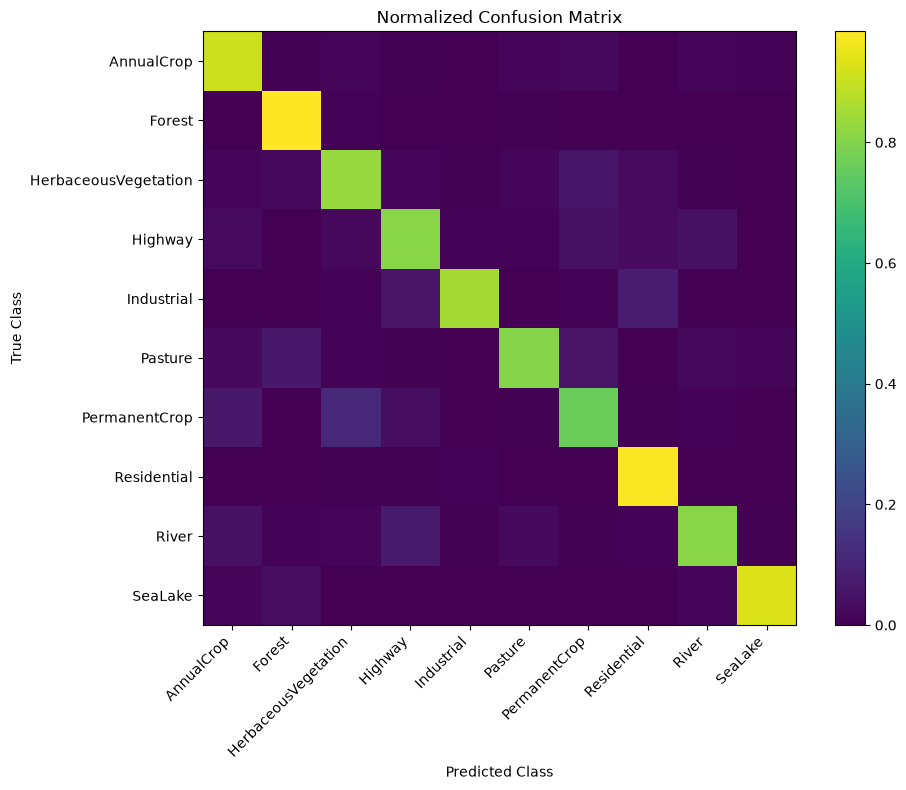

In [28]:
from sklearn.metrics import confusion_matrix

all_labels = []
all_predictions = []

trainednet.eval()

with torch.no_grad():

    for data in testloader:

        images, labels = data

        images = images.to(device)

        outputs = trainednet(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize='true'
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(10),
    classes,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(10),
    classes
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')

plt.title('Normalized Confusion Matrix')

plt.tight_layout()

plt.show()

In [30]:
print("===================================")
print("STAGE 1 - BASELINE RESULTS")
print("===================================")

print("Model: Baseline CNN")
print("Classes:", len(classes))
print("Batch size:", batch_size)
print("Epochs:", n_epochs)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Total parameters:", total_params)

print(
    "Best validation accuracy: %.2f%%"
    % (100 * max(val_accuracies))
)

print(
    "Final test accuracy: %.2f%%"
    % (100 * correct / total)
)

print("Checkpoint: baseline.pth")

STAGE 1 - BASELINE RESULTS
Model: Baseline CNN
Classes: 10
Batch size: 64
Epochs: 10
Optimizer: Adam
Learning rate: 0.001
Total parameters: 2193226
Best validation accuracy: 87.26%
Final test accuracy: 87.26%
Checkpoint: baseline.pth
